# Tutorial Class 11 Set 01

In [1]:
library(httr)
library(jsonlite)
library(tidyverse)
library(DBI)
library(duckdb)
library(scales)

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.0     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.2     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.1     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter()  masks stats::filter()
✖ purrr::flatten() masks jsonlite::flatten()
✖ dplyr::lag()     masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors

Attaching package: ‘scales’


The following object is masked from ‘package:purrr’:

    discard


The following object is masked from ‘package:readr’:

    col_factor




## Prepare this Exercise before Class

### Exercise 1

In [2]:
fred_key <- "6a4cdf9e5dbd446889a0e3a89cda1579"

### Exercise 2

In [3]:
unrate_series_id <- "UNRATE"

unrate_response <-
  GET(
    url = "https://api.stlouisfed.org/fred/series/observations",
    query = list(
      series_id = unrate_series_id,
      api_key = fred_key,
      file_type = "json"
    )
  )

status_code(unrate_response)
http_type(unrate_response)

[1] 200

[1] "application/json"

In [4]:
cpi_series_id <- "CPIAUCSL"

cpi_response <-
  GET(
    url = "https://api.stlouisfed.org/fred/series/observations",
    query = list(
      series_id = cpi_series_id,
      api_key = fred_key,
      file_type = "json"
    )
  )

status_code(cpi_response)
http_type(cpi_response)

[1] 200

[1] "application/json"

In [5]:
fedfunds_series_id <- "FEDFUNDS"

fedfunds_response <-
  GET(
    url = "https://api.stlouisfed.org/fred/series/observations",
    query = list(
      series_id = fedfunds_series_id,
      api_key = fred_key,
      file_type = "json"
    )
  )

status_code(fedfunds_response)
http_type(fedfunds_response)

[1] 200

[1] "application/json"

### Exercise 3

In [6]:
unrate_json_text <- content(unrate_response, as = "text", encoding = "UTF-8")

unrate_list <-
  fromJSON(
    unrate_json_text,
    simplifyVector = FALSE
  )

names(unrate_list)
names(unrate_list$observations[[1]])
unrate_list$observations[[1]]

unrate_raw <-
  tibble(record = unrate_list$observations) |>
  unnest_wider(record)

head(unrate_raw)
glimpse(unrate_raw)

unrate_tidy <-
  unrate_raw |>
  transmute(
    date = date,
    unrate = value
  )

head(unrate_tidy)
glimpse(unrate_tidy)

[1] "realtime_start"    "realtime_end"      "observation_start"
 [4] "observation_end"   "units"             "output_type"      
 [7] "file_type"         "order_by"          "sort_order"       
[10] "count"             "offset"            "limit"            
[13] "observations"

[1] "realtime_start" "realtime_end"   "date"           "value"

$realtime_start
[1] "2026-06-16"

$realtime_end
[1] "2026-06-16"

$date
[1] "1948-01-01"

$value
[1] "3.4"

realtime_start,realtime_end,date,value
<chr>,<chr>,<chr>,<chr>
2026-06-16,2026-06-16,1948-01-01,3.4
2026-06-16,2026-06-16,1948-02-01,3.8
2026-06-16,2026-06-16,1948-03-01,4.0
2026-06-16,2026-06-16,1948-04-01,3.9
2026-06-16,2026-06-16,1948-05-01,3.5
2026-06-16,2026-06-16,1948-06-01,3.6


Rows: 941
Columns: 4
$ realtime_start <chr> "2026-06-16", "2026-06-16", "2026-06-16", "2026-06-16",…
$ realtime_end   <chr> "2026-06-16", "2026-06-16", "2026-06-16", "2026-06-16",…
$ date           <chr> "1948-01-01", "1948-02-01", "1948-03-01", "1948-04-01",…
$ value          <chr> "3.4", "3.8", "4.0", "3.9", "3.5", "3.6", "3.6", "3.9",…


date,unrate
<chr>,<chr>
1948-01-01,3.4
1948-02-01,3.8
1948-03-01,4.0
1948-04-01,3.9
1948-05-01,3.5
1948-06-01,3.6


Rows: 941
Columns: 2
$ date   <chr> "1948-01-01", "1948-02-01", "1948-03-01", "1948-04-01", "1948-0…
$ unrate <chr> "3.4", "3.8", "4.0", "3.9", "3.5", "3.6", "3.6", "3.9", "3.8", …


In [7]:
cpi_json_text <- content(cpi_response, as = "text", encoding = "UTF-8")

cpi_list <-
  fromJSON(
    cpi_json_text,
    simplifyVector = FALSE
  )

cpi_raw <-
  tibble(record = cpi_list$observations) |>
  unnest_wider(record)

head(cpi_raw)
glimpse(cpi_raw)

cpi_tidy <-
  cpi_raw |>
  transmute(
    date = date,
    cpi = value
  )

head(cpi_tidy)
glimpse(cpi_tidy)

realtime_start,realtime_end,date,value
<chr>,<chr>,<chr>,<chr>
2026-06-10,2026-06-10,1947-01-01,21.48
2026-06-10,2026-06-10,1947-02-01,21.62
2026-06-10,2026-06-10,1947-03-01,22.0
2026-06-10,2026-06-10,1947-04-01,22.0
2026-06-10,2026-06-10,1947-05-01,21.95
2026-06-10,2026-06-10,1947-06-01,22.08


Rows: 953
Columns: 4
$ realtime_start <chr> "2026-06-10", "2026-06-10", "2026-06-10", "2026-06-10",…
$ realtime_end   <chr> "2026-06-10", "2026-06-10", "2026-06-10", "2026-06-10",…
$ date           <chr> "1947-01-01", "1947-02-01", "1947-03-01", "1947-04-01",…
$ value          <chr> "21.48", "21.62", "22.0", "22.0", "21.95", "22.08", "22…


date,cpi
<chr>,<chr>
1947-01-01,21.48
1947-02-01,21.62
1947-03-01,22.0
1947-04-01,22.0
1947-05-01,21.95
1947-06-01,22.08


Rows: 953
Columns: 2
$ date <chr> "1947-01-01", "1947-02-01", "1947-03-01", "1947-04-01", "1947-05-…
$ cpi  <chr> "21.48", "21.62", "22.0", "22.0", "21.95", "22.08", "22.23", "22.…


In [8]:
fedfunds_json_text <- content(fedfunds_response, as = "text", encoding = "UTF-8")

fedfunds_list <-
  fromJSON(
    fedfunds_json_text,
    simplifyVector = FALSE
  )

fedfunds_raw <-
  tibble(record = fedfunds_list$observations) |>
  unnest_wider(record)

head(fedfunds_raw)
glimpse(fedfunds_raw)

fedfunds_tidy <-
  fedfunds_raw |>
  transmute(
    date = date,
    fedfunds = value
  )

head(fedfunds_tidy)
glimpse(fedfunds_tidy)

realtime_start,realtime_end,date,value
<chr>,<chr>,<chr>,<chr>
2026-06-02,2026-06-02,1954-07-01,0.80
2026-06-02,2026-06-02,1954-08-01,1.22
2026-06-02,2026-06-02,1954-09-01,1.07
2026-06-02,2026-06-02,1954-10-01,0.85
2026-06-02,2026-06-02,1954-11-01,0.83
2026-06-02,2026-06-02,1954-12-01,1.28


Rows: 863
Columns: 4
$ realtime_start <chr> "2026-06-02", "2026-06-02", "2026-06-02", "2026-06-02",…
$ realtime_end   <chr> "2026-06-02", "2026-06-02", "2026-06-02", "2026-06-02",…
$ date           <chr> "1954-07-01", "1954-08-01", "1954-09-01", "1954-10-01",…
$ value          <chr> "0.80", "1.22", "1.07", "0.85", "0.83", "1.28", "1.39",…


date,fedfunds
<chr>,<chr>
1954-07-01,0.80
1954-08-01,1.22
1954-09-01,1.07
1954-10-01,0.85
1954-11-01,0.83
1954-12-01,1.28


Rows: 863
Columns: 2
$ date     <chr> "1954-07-01", "1954-08-01", "1954-09-01", "1954-10-01", "1954…
$ fedfunds <chr> "0.80", "1.22", "1.07", "0.85", "0.83", "1.28", "1.39", "1.29…


### Exercise 4

In [9]:
unrate_clean <-
  unrate_tidy |>
  transmute(
    date = as.Date(date),
    unrate = na_if(unrate, ".") |> as.numeric()
  )

head(unrate_clean)
glimpse(unrate_clean)

date,unrate
<date>,<dbl>
1948-01-01,3.4
1948-02-01,3.8
1948-03-01,4.0
1948-04-01,3.9
1948-05-01,3.5
1948-06-01,3.6


Rows: 941
Columns: 2
$ date   <date> 1948-01-01, 1948-02-01, 1948-03-01, 1948-04-01, 1948-05-01, 19…
$ unrate <dbl> 3.4, 3.8, 4.0, 3.9, 3.5, 3.6, 3.6, 3.9, 3.8, 3.7, 3.8, 4.0, 4.3…


In [10]:
cpi_clean <-
  cpi_tidy |>
  transmute(
    date = as.Date(date),
    cpi = na_if(cpi, ".") |> as.numeric()
  )

head(cpi_clean)
glimpse(cpi_clean)

date,cpi
<date>,<dbl>
1947-01-01,21.48
1947-02-01,21.62
1947-03-01,22.00
1947-04-01,22.00
1947-05-01,21.95
1947-06-01,22.08


Rows: 953
Columns: 2
$ date <date> 1947-01-01, 1947-02-01, 1947-03-01, 1947-04-01, 1947-05-01, 1947…
$ cpi  <dbl> 21.48, 21.62, 22.00, 22.00, 21.95, 22.08, 22.23, 22.40, 22.84, 22…


In [11]:
fedfunds_clean <-
  fedfunds_tidy |>
  transmute(
    date = as.Date(date),
    fedfunds = na_if(fedfunds, ".") |> as.numeric()
  )

head(fedfunds_clean)
glimpse(fedfunds_clean)

date,fedfunds
<date>,<dbl>
1954-07-01,0.80
1954-08-01,1.22
1954-09-01,1.07
1954-10-01,0.85
1954-11-01,0.83
1954-12-01,1.28


Rows: 863
Columns: 2
$ date     <date> 1954-07-01, 1954-08-01, 1954-09-01, 1954-10-01, 1954-11-01, …
$ fedfunds <dbl> 0.80, 1.22, 1.07, 0.85, 0.83, 1.28, 1.39, 1.29, 1.35, 1.43, 1…


In [12]:
dir.create("data", showWarnings = FALSE)

con <-
  dbConnect(
    duckdb(),
    dbdir = "data/fred.duckdb"
  )

dbWriteTable(
  con,
  "unrate_observations",
  unrate_clean,
  overwrite = TRUE
)

dbWriteTable(
  con,
  "cpi_observations",
  cpi_clean,
  overwrite = TRUE
)

dbWriteTable(
  con,
  "fedfunds_observations",
  fedfunds_clean,
  overwrite = TRUE
)

dbListTables(con)

[1] "cpi_observations"      "fedfunds_observations" "unrate_observations"

### Exercise 5

In [13]:
unrate_db <-
  tbl(con, "unrate_observations")

unrate_summary <-
  unrate_db |>
  filter(date >= "2000-01-01") |>
  summarise(
    average_unrate = mean(unrate, na.rm = TRUE),
    minimum_unrate = min(unrate, na.rm = TRUE),
    maximum_unrate = max(unrate, na.rm = TRUE)
  ) |>
  collect()

unrate_summary

average_unrate,minimum_unrate,maximum_unrate
<dbl>,<dbl>,<dbl>
5.623418,3.4,14.8


In [14]:
cpi_db <-
  tbl(con, "cpi_observations")

cpi_summary <-
  cpi_db |>
  filter(date >= "2000-01-01") |>
  summarise(
    average_cpi = mean(cpi, na.rm = TRUE),
    minimum_cpi = min(cpi, na.rm = TRUE),
    maximum_cpi = max(cpi, na.rm = TRUE)
  ) |>
  collect()

cpi_summary

average_cpi,minimum_cpi,maximum_cpi
<dbl>,<dbl>,<dbl>
234.7093,169.3,333.979


In [15]:
fedfunds_db <-
  tbl(con, "fedfunds_observations")

fedfunds_summary <-
  fedfunds_db |>
  filter(date >= "2000-01-01") |>
  summarise(
    average_fedfunds = mean(fedfunds, na.rm = TRUE),
    minimum_fedfunds = min(fedfunds, na.rm = TRUE),
    maximum_fedfunds = max(fedfunds, na.rm = TRUE)
  ) |>
  collect()

fedfunds_summary

average_fedfunds,minimum_fedfunds,maximum_fedfunds
<dbl>,<dbl>,<dbl>
2.033502,0.05,6.54


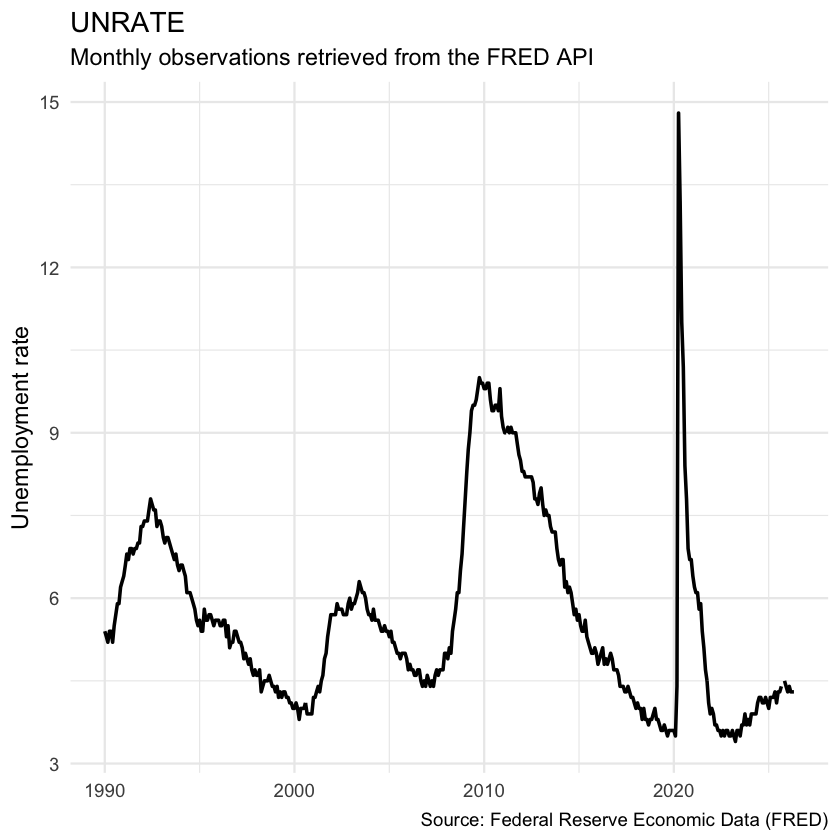

In [16]:
unrate_plot_data <-
  unrate_db |>
  filter(date >= "1990-01-01") |>
  collect()

ggplot(
  unrate_plot_data,
  aes(
    x = date,
    y = unrate
  )
) +
  geom_line(linewidth = 1) +
  labs(
    title = "UNRATE",
    subtitle = "Monthly observations retrieved from the FRED API",
    x = NULL,
    y = "Unemployment rate",
    caption = "Source: Federal Reserve Economic Data (FRED)"
  ) +
  theme_minimal(base_size = 14)

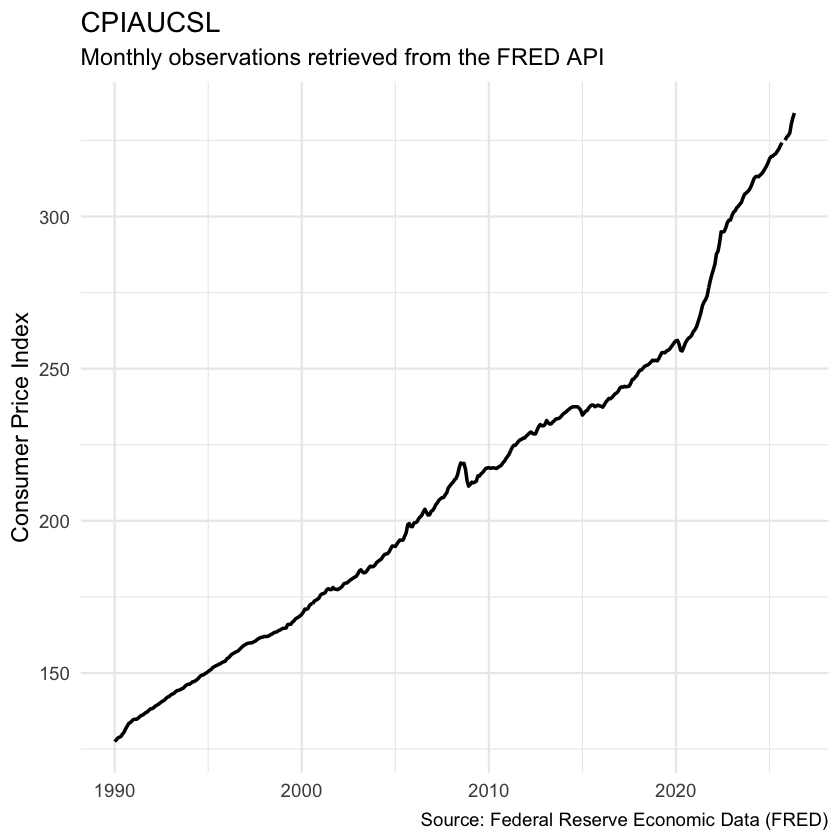

In [17]:
cpi_plot_data <-
  cpi_db |>
  filter(date >= "1990-01-01") |>
  collect()

ggplot(
  cpi_plot_data,
  aes(
    x = date,
    y = cpi
  )
) +
  geom_line(linewidth = 1) +
  labs(
    title = "CPIAUCSL",
    subtitle = "Monthly observations retrieved from the FRED API",
    x = NULL,
    y = "Consumer Price Index",
    caption = "Source: Federal Reserve Economic Data (FRED)"
  ) +
  theme_minimal(base_size = 14)

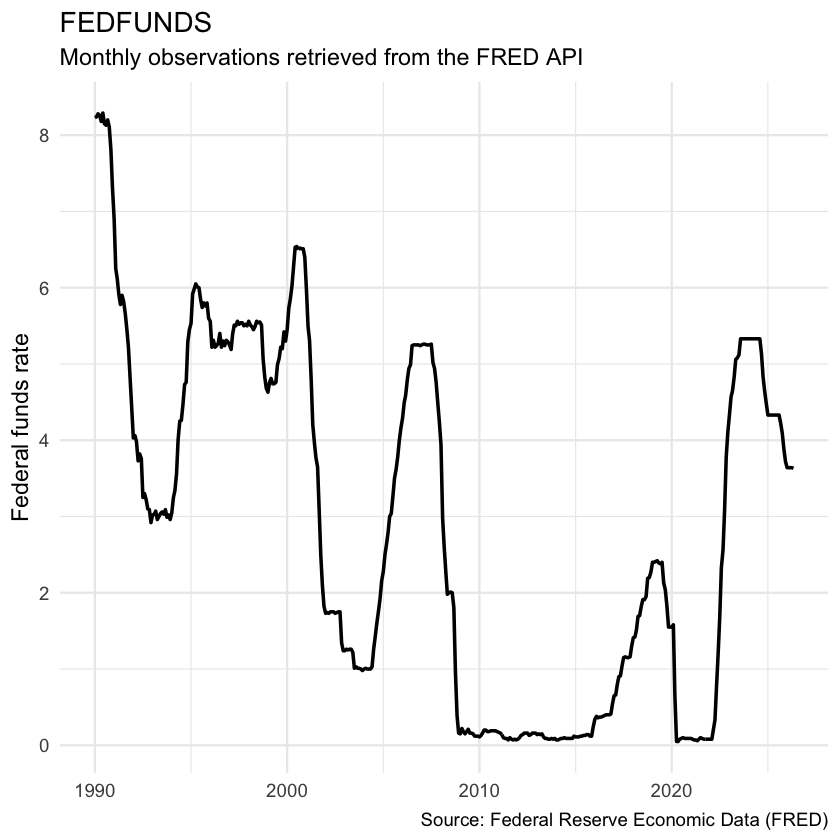

In [18]:
fedfunds_plot_data <-
  fedfunds_db |>
  filter(date >= "1990-01-01") |>
  collect()

ggplot(
  fedfunds_plot_data,
  aes(
    x = date,
    y = fedfunds
  )
) +
  geom_line(linewidth = 1) +
  labs(
    title = "FEDFUNDS",
    subtitle = "Monthly observations retrieved from the FRED API",
    x = NULL,
    y = "Federal funds rate",
    caption = "Source: Federal Reserve Economic Data (FRED)"
  ) +
  theme_minimal(base_size = 14)